In [1]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import plotly.express as px

plt.style.use("ggplot")
sns.set_style("whitegrid")

plt.rcParams["figure.figsize"] = (10,6)

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_csv("../data/processed/merged_clean_dataset.csv")

print("Dataset Loaded Successfully")

Dataset Loaded Successfully


In [3]:
df.head()

,index,Order ID,Date,Status,Fulfilment,Sales Channel,ship-service-level,Style,SKU,Category,Size,ASIN,Courier Status,Qty,currency,Amount,ship-city,ship-state,ship-postal-code,ship-country,promotion-ids,B2B,fulfilled-by,Month,is_cancelled,SKU Code,Design No.,Stock,Category_stock,Size_stock,Color
0,0,405-8078784-5731545,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,SET389,SET389-KR-NP-S,SET,S,B09KXVBD7Z,NaN,0,INR,647.62,MUMBAI,MAHARASHTRA,400081.0,IN,NaN,False,Easy Ship,2022-04,True,SET389-KR-NP-S,SET389,32.0,SET,S,White
1,1,171-9198151-1101146,2022-04-30,Shipped - Delivered to Buyer,Merchant,Amazon.in,Standard,JNE3781,JNE3781-KR-XXXL,KURTA,3XL,B09K3WFS32,Shipped,1,INR,406.00,BENGALURU,KARNATAKA,560085.0,IN,Amazon PLCC Free-Financing Universal Merchant ...,False,Easy Ship,2022-04,False,JNE3781-KR-XXXL,JNE3781,96.0,KURTA,XXXL,Green
2,2,404-0687676-7273146,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3371,JNE3371-KR-XL,KURTA,XL,B07WV4JV4D,Shipped,1,INR,329.00,NAVI MUMBAI,MAHARASHTRA,410210.0,IN,IN Core Free Shipping 2015/04/08 23-48-5-108,True,NaN,2022-04,False,JNE3371-KR-XL,JNE3371,4.0,KURTA,XL,Light Green
3,3,403-9615377-8133951,2022-04-30,Cancelled,Merchant,Amazon.in,Standard,J0341,J0341-DR-L,WESTERN DRESS,L,B099NRCT7B,NaN,0,INR,753.33,PUDUCHERRY,PUDUCHERRY,605008.0,IN,NaN,False,Easy Ship,2022-04,True,J0341-DR-L,J0341,193.0,DRESS,L,Blue
4,4,407-1069790-7240320,2022-04-30,Shipped,Amazon,Amazon.in,Expedited,JNE3671,JNE3671-TU-XXXL,TOP,3XL,B098714BZP,Shipped,1,INR,574.00,CHENNAI,TAMIL NADU,600073.0,IN,NaN,False,NaN,2022-04,False,JNE3671-TU-XXXL,JNE3671,6.0,TUNIC,XXXL,Pink


In [4]:
print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")

Rows    : 128,975
Columns : 31


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 128975 entries, 0 to 128974
Data columns (total 31 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   index               128975 non-null  int64  
 1   Order ID            128975 non-null  str    
 2   Date                128975 non-null  str    
 3   Status              128975 non-null  str    
 4   Fulfilment          128975 non-null  str    
 5   Sales Channel       128975 non-null  str    
 6   ship-service-level  128975 non-null  str    
 7   Style               128975 non-null  str    
 8   SKU                 128975 non-null  str    
 9   Category            128975 non-null  str    
 10  Size                128975 non-null  str    
 11  ASIN                128975 non-null  str    
 12  Courier Status      122103 non-null  str    
 13  Qty                 128975 non-null  int64  
 14  currency            121180 non-null  str    
 15  Amount              121180 non-null  float64


In [6]:
df.columns.tolist()

['index',
 'Order ID',
 'Date',
 'Status',
 'Fulfilment',
 'Sales Channel ',
 'ship-service-level',
 'Style',
 'SKU',
 'Category',
 'Size',
 'ASIN',
 'Courier Status',
 'Qty',
 'currency',
 'Amount',
 'ship-city',
 'ship-state',
 'ship-postal-code',
 'ship-country',
 'promotion-ids',
 'B2B',
 'fulfilled-by',
 'Month',
 'is_cancelled',
 'SKU Code',
 'Design No.',
 'Stock',
 'Category_stock',
 'Size_stock',
 'Color']

In [7]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
index,128975.0,NaN,NaN,NaN,64487.0,37232.019822,0.0,32243.5,64487.0,96730.5,128974.0
Order ID,128975,120378,403-4984515-8861958,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,128975,91,2022-05-03,2085,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,128975,13,Shipped,77804,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fulfilment,128975,2,Amazon,89698,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales Channel,128975,2,Amazon.in,128851,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ship-service-level,128975,2,Expedited,88615,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Style,128975,1377,JNE3797,4224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SKU,128975,7195,JNE3797-KR-L,773,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,128975,9,SET,50284,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage": round(df.isnull().mean()*100,2)
})

missing = missing[missing["Missing Values"] > 0]

missing.sort_values("Missing Values", ascending=False)

,Missing Values,Percentage
fulfilled-by,89698,69.55
promotion-ids,49153,38.11
currency,7795,6.04
Amount,7795,6.04
SKU Code,7706,5.97
Design No.,7706,5.97
Stock,7706,5.97
Size_stock,7706,5.97
Category_stock,7706,5.97
Color,7706,5.97


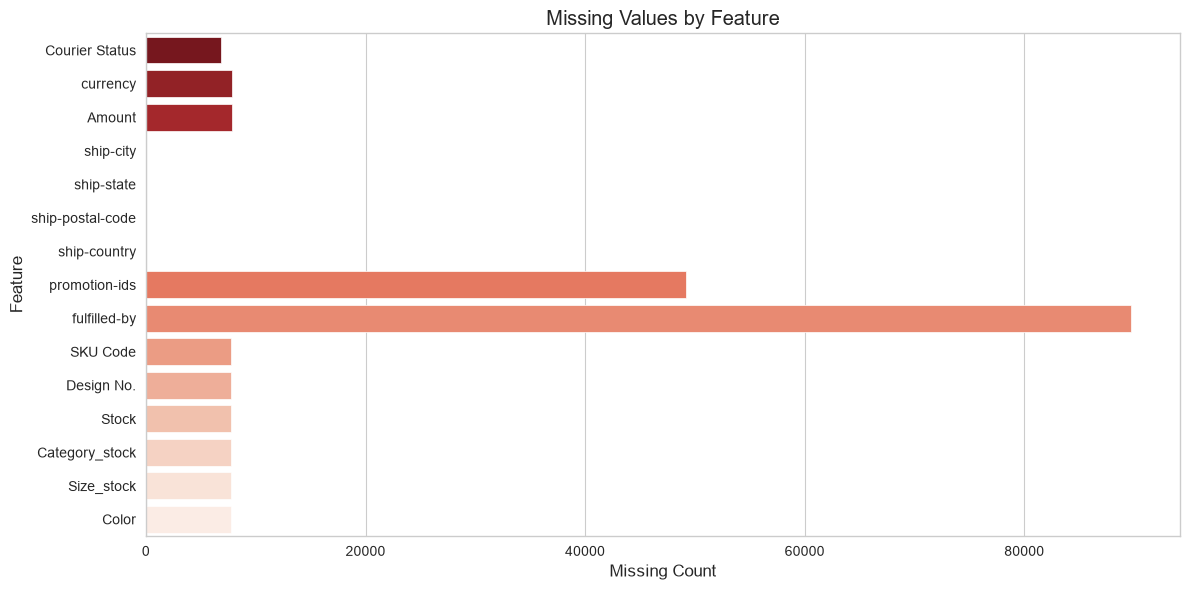

In [9]:
plt.figure(figsize=(12,6))

sns.barplot(
    x=missing["Missing Values"],
    y=missing.index,
    palette="Reds_r"
)

plt.title("Missing Values by Feature")
plt.xlabel("Missing Count")
plt.ylabel("Feature")

plt.tight_layout()

plt.savefig("../images/missing_values.png", dpi=300)

plt.show()

In [10]:
duplicates = df.duplicated().sum()

print(f"Duplicate Records : {duplicates}")

Duplicate Records : 0


In [11]:
unique = pd.DataFrame({
    "Unique Values": df.nunique()
})

unique.sort_values("Unique Values", ascending=False)

,Unique Values
index,128975
Order ID,120378
ship-postal-code,9459
ship-city,8955
SKU,7195
ASIN,7190
SKU Code,6617
promotion-ids,5787
Amount,1410
Style,1377


In [12]:
numerical = df.select_dtypes(include=["int64","float64"]).columns

categorical = df.select_dtypes(include=["object","bool"]).columns

print("Numerical Features")
print(numerical)

print("\nCategorical Features")
print(categorical)

Numerical Features
Index(['index', 'Qty', 'Amount', 'ship-postal-code', 'Stock'], dtype='str')

Categorical Features
Index(['Order ID', 'Date', 'Status', 'Fulfilment', 'Sales Channel ',
       'ship-service-level', 'Style', 'SKU', 'Category', 'Size', 'ASIN',
       'Courier Status', 'currency', 'ship-city', 'ship-state', 'ship-country',
       'promotion-ids', 'B2B', 'fulfilled-by', 'Month', 'is_cancelled',
       'SKU Code', 'Design No.', 'Category_stock', 'Size_stock', 'Color'],
      dtype='str')


Category
SET              50284
KURTA            49877
WESTERN DRESS    15500
TOP              10622
ETHNIC DRESS      1159
BLOUSE             926
BOTTOM             440
SAREE              164
DUPATTA              3
Name: count, dtype: int64


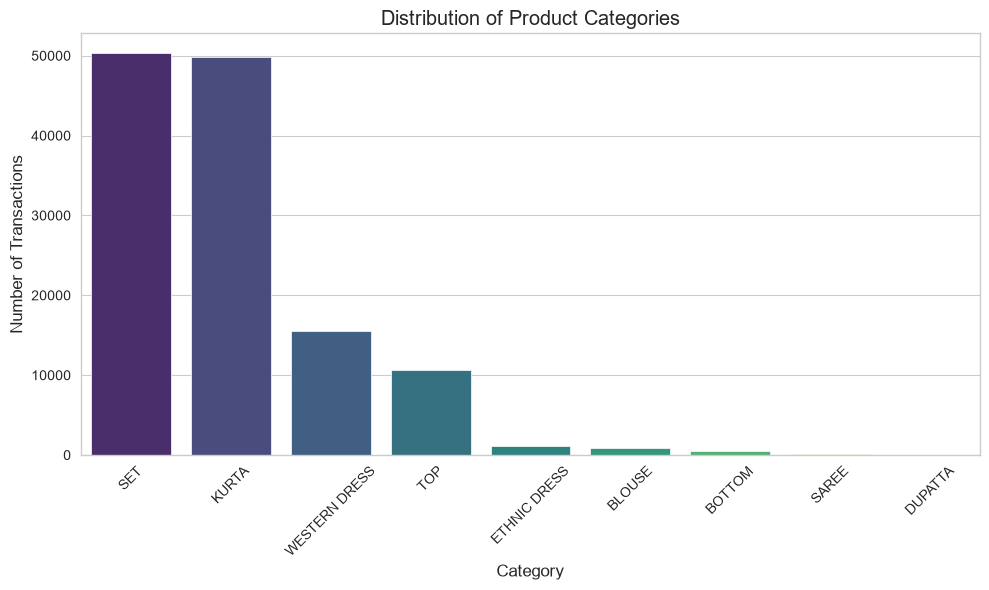

In [13]:
category_counts = df["Category"].value_counts()

print(category_counts)

plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    x="Category",
    order=category_counts.index,
    palette="viridis"
)

plt.title("Distribution of Product Categories")
plt.xlabel("Category")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("../images/category_distribution.png", dpi=300)
plt.show()

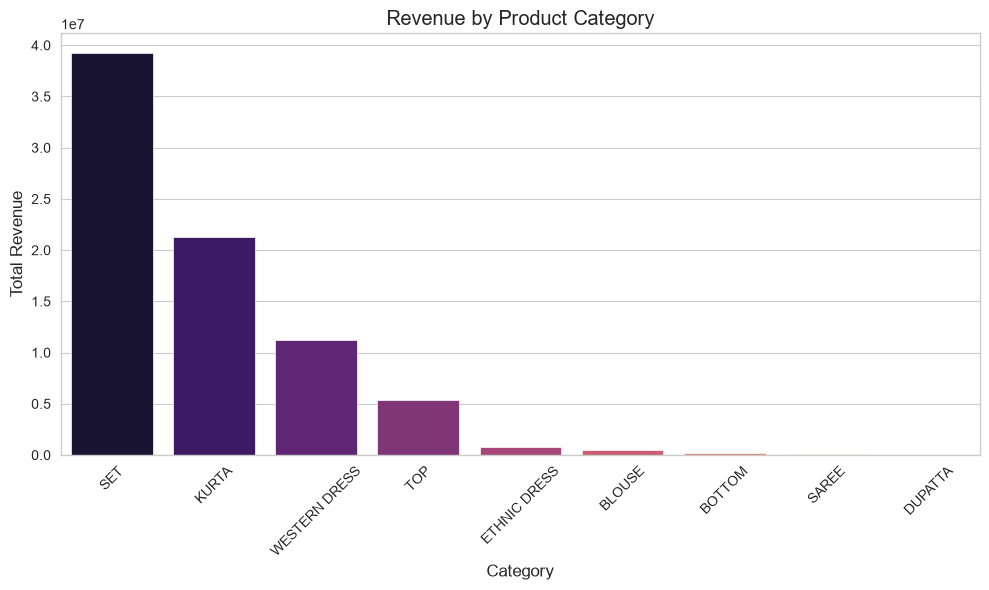

Category
SET              39204124.03
KURTA            21299546.70
WESTERN DRESS    11216072.69
TOP               5347792.30
ETHNIC DRESS       791217.66
BLOUSE             458408.18
BOTTOM             150667.98
SAREE              123933.76
DUPATTA               915.00
Name: Amount, dtype: float64

In [14]:
category_sales = (
    df.groupby("Category")["Amount"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=category_sales.index,
    y=category_sales.values,
    palette="magma"
)

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Revenue")

plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("../images/revenue_by_category.png", dpi=300)
plt.show()

category_sales

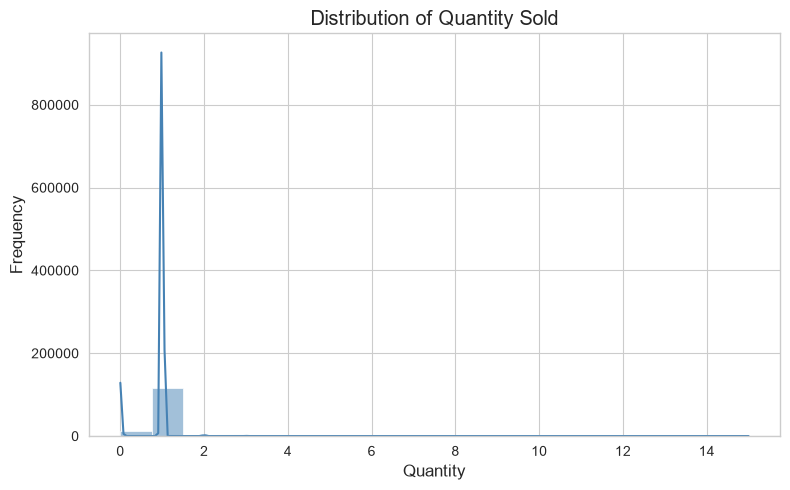

In [15]:
plt.figure(figsize=(8,5))

sns.histplot(
    df["Qty"],
    bins=20,
    kde=True,
    color="steelblue"
)

plt.title("Distribution of Quantity Sold")
plt.xlabel("Quantity")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("../images/quantity_distribution.png", dpi=300)
plt.show()

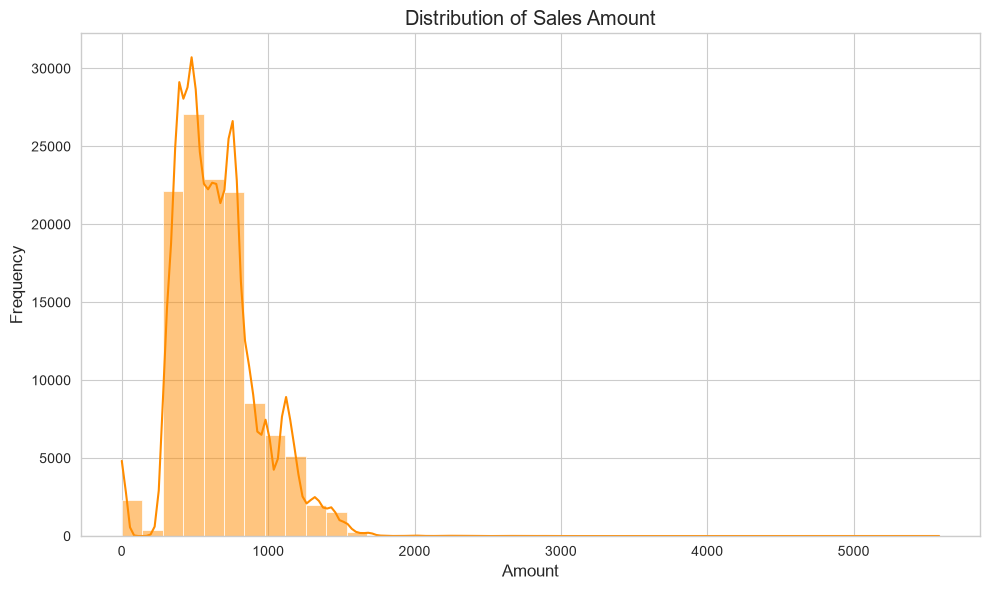

In [16]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["Amount"],
    bins=40,
    kde=True,
    color="darkorange"
)

plt.title("Distribution of Sales Amount")
plt.xlabel("Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.savefig("../images/sales_amount_distribution.png", dpi=300)
plt.show()

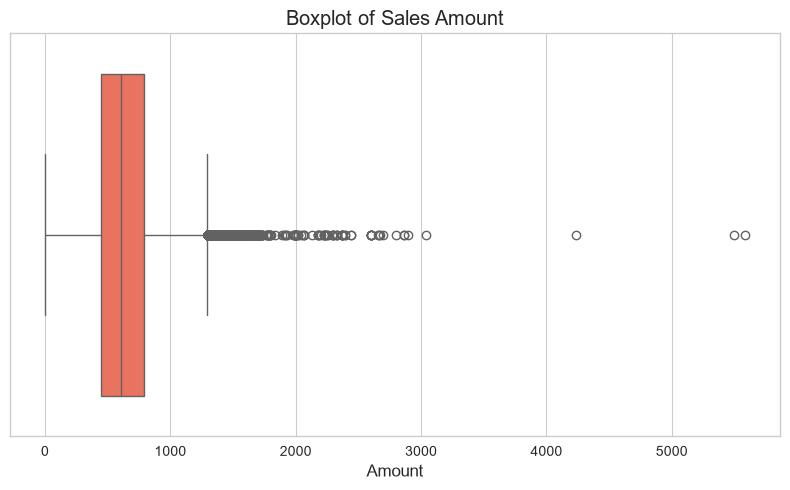

In [17]:
plt.figure(figsize=(8,5))

sns.boxplot(
    x=df["Amount"],
    color="tomato"
)

plt.title("Boxplot of Sales Amount")

plt.tight_layout()
plt.savefig("../images/amount_boxplot.png", dpi=300)
plt.show()

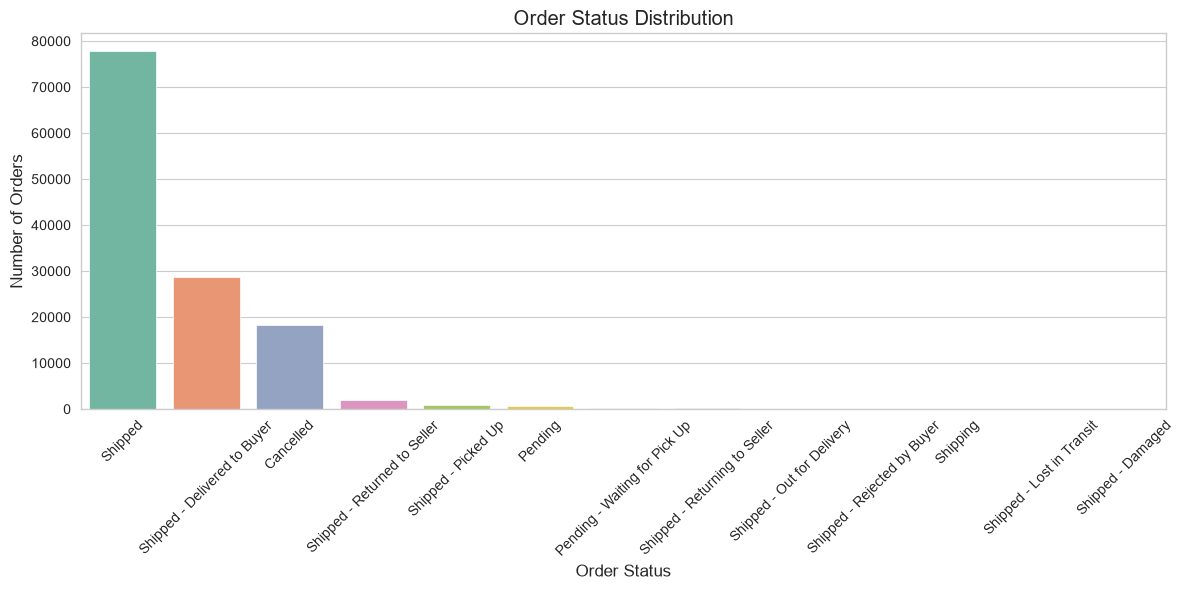

Status
Shipped                          77804
Shipped - Delivered to Buyer     28769
Cancelled                        18332
Shipped - Returned to Seller      1953
Shipped - Picked Up                973
Pending                            658
Pending - Waiting for Pick Up      281
Shipped - Returning to Seller      145
Shipped - Out for Delivery          35
Shipped - Rejected by Buyer         11
Shipping                             8
Shipped - Lost in Transit            5
Shipped - Damaged                    1
Name: count, dtype: int64

In [18]:
status = df["Status"].value_counts()

plt.figure(figsize=(12,6))

sns.barplot(
    x=status.index,
    y=status.values,
    palette="Set2"
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)

plt.tight_layout()
plt.savefig("../images/order_status_distribution.png", dpi=300)
plt.show()

status

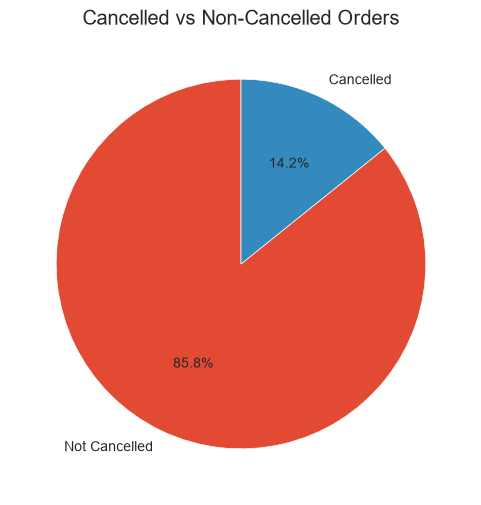

In [19]:
cancel = df["is_cancelled"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    cancel,
    labels=["Not Cancelled", "Cancelled"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Cancelled vs Non-Cancelled Orders")

plt.savefig("../images/cancellation_pie.png", dpi=300)

plt.show()

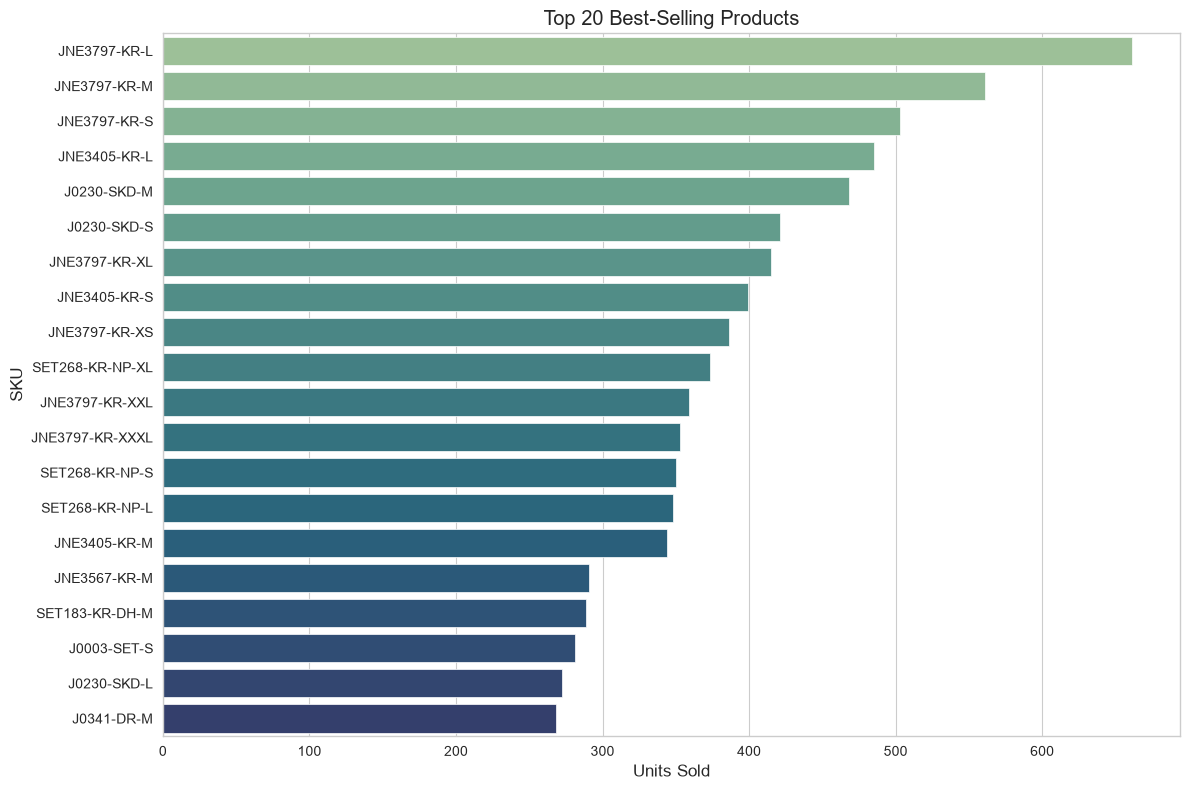

In [20]:
top_products = (
    df.groupby("SKU")["Qty"]
      .sum()
      .sort_values(ascending=False)
      .head(20)
)

plt.figure(figsize=(12,8))

sns.barplot(
    x=top_products.values,
    y=top_products.index,
    palette="crest"
)

plt.title("Top 20 Best-Selling Products")
plt.xlabel("Units Sold")
plt.ylabel("SKU")

plt.tight_layout()
plt.savefig("../images/top_products.png", dpi=300)
plt.show()

In [21]:
df["Date"] = pd.to_datetime(df["Date"])

print(df["Date"].min())
print(df["Date"].max())

2022-03-31 00:00:00
2022-06-29 00:00:00


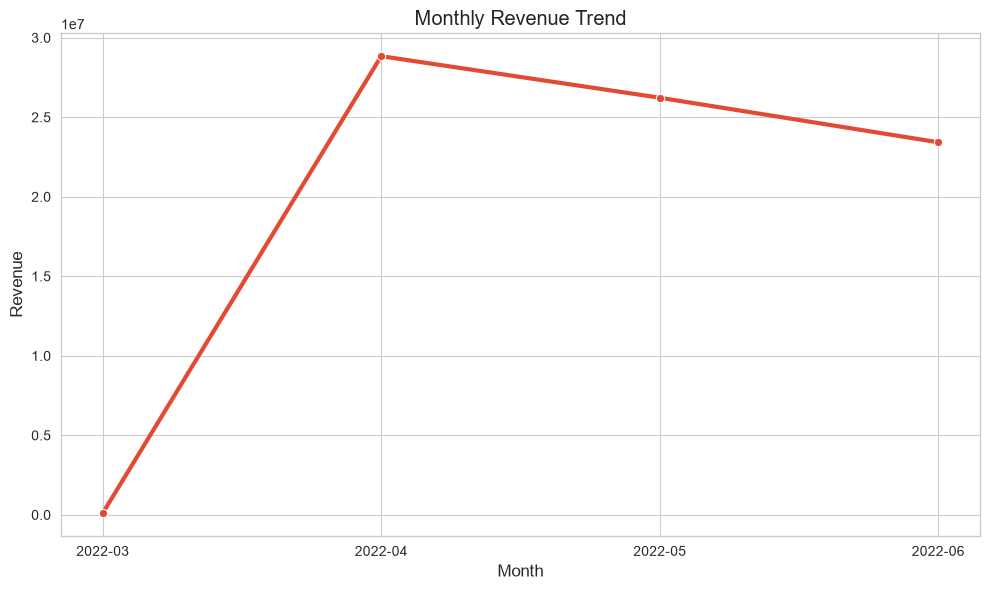

,Month,Amount
0,2022-03,101683.85
1,2022-04,28838708.32
2,2022-05,26226476.75
3,2022-06,23425809.38


In [22]:
monthly_sales = (
    df.groupby("Month")["Amount"]
      .sum()
      .reset_index()
)

plt.figure(figsize=(10,6))

sns.lineplot(
    data=monthly_sales,
    x="Month",
    y="Amount",
    marker="o",
    linewidth=3
)

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")

plt.tight_layout()
plt.savefig("../images/monthly_sales_trend.png", dpi=300)
plt.show()

monthly_sales

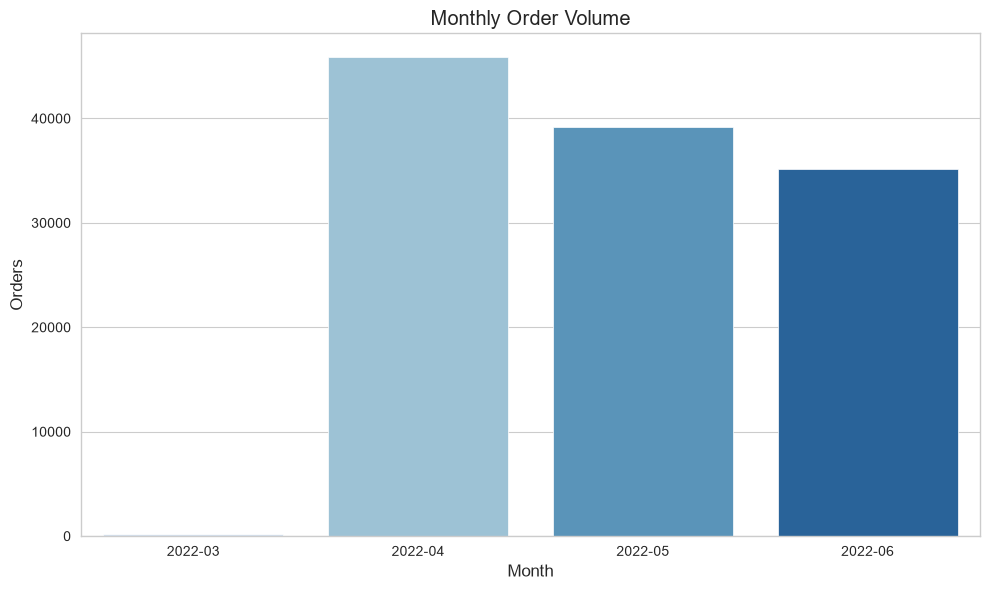

In [23]:
monthly_orders = (
    df.groupby("Month")["Order ID"]
      .nunique()
      .reset_index(name="Orders")
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=monthly_orders,
    x="Month",
    y="Orders",
    palette="Blues"
)

plt.title("Monthly Order Volume")

plt.tight_layout()
plt.savefig("../images/monthly_orders.png", dpi=300)
plt.show()

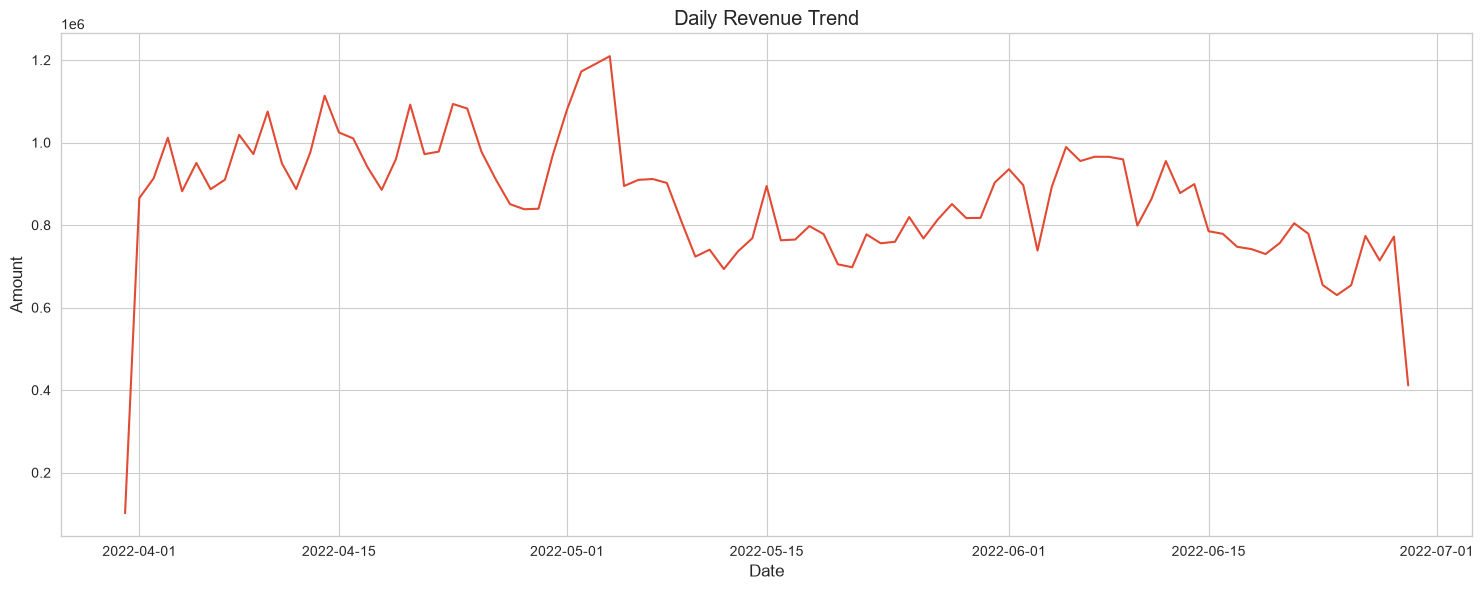

In [24]:
daily_sales = (
    df.groupby("Date")["Amount"]
      .sum()
      .reset_index()
)

plt.figure(figsize=(15,6))

sns.lineplot(
    data=daily_sales,
    x="Date",
    y="Amount"
)

plt.title("Daily Revenue Trend")

plt.tight_layout()
plt.savefig("../images/daily_sales.png", dpi=300)
plt.show()

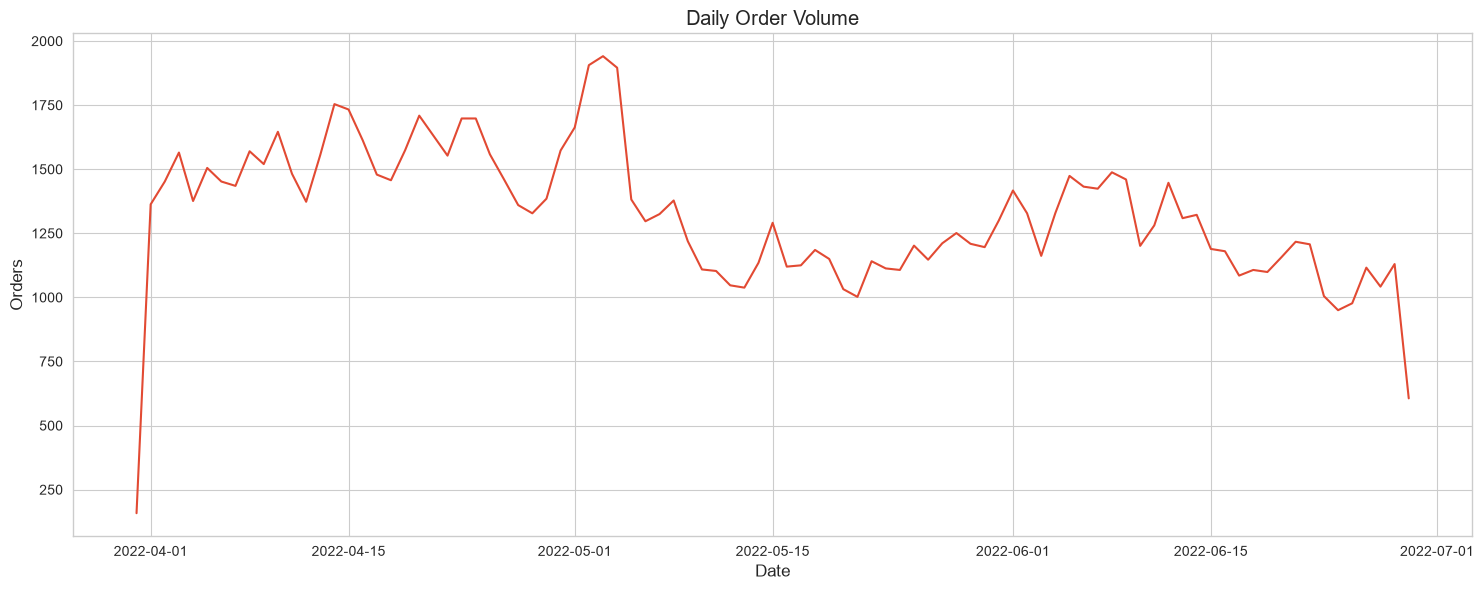

In [25]:
daily_orders = (
    df.groupby("Date")["Order ID"]
      .nunique()
      .reset_index(name="Orders")
)

plt.figure(figsize=(15,6))

sns.lineplot(
    data=daily_orders,
    x="Date",
    y="Orders"
)

plt.title("Daily Order Volume")

plt.tight_layout()
plt.savefig("../images/daily_orders.png", dpi=300)
plt.show()

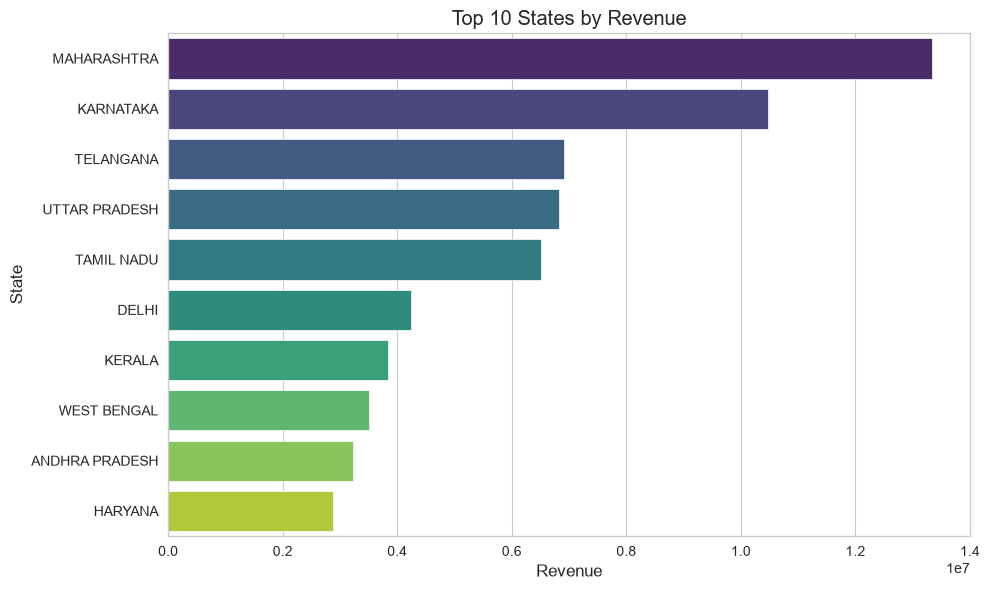

In [26]:
top_states = (
    df.groupby("ship-state")["Amount"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_states.values,
    y=top_states.index,
    palette="viridis"
)

plt.title("Top 10 States by Revenue")
plt.xlabel("Revenue")
plt.ylabel("State")

plt.tight_layout()
plt.savefig("../images/top_states_revenue.png", dpi=300)
plt.show()

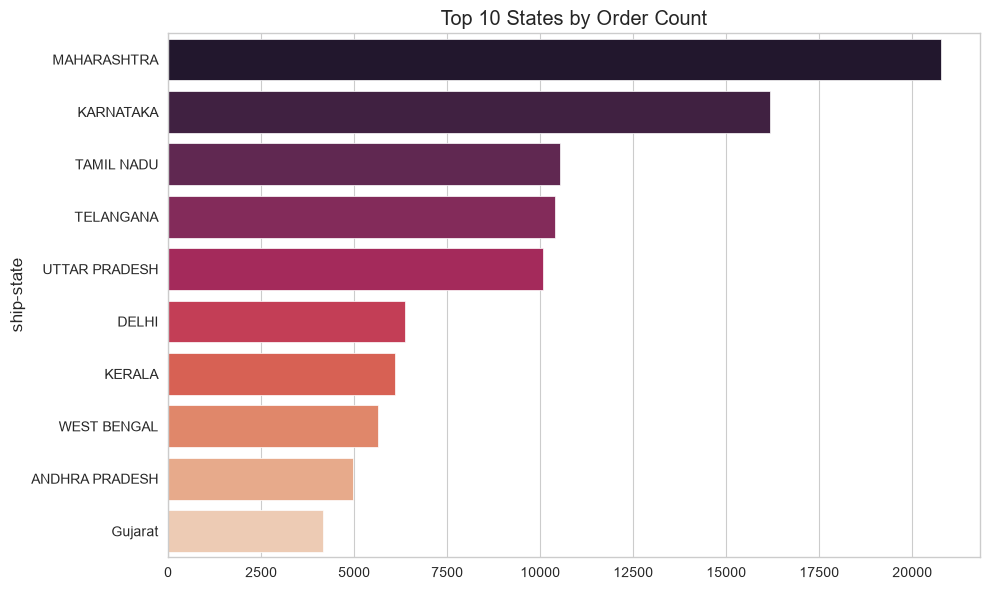

In [27]:
state_orders = (
    df.groupby("ship-state")["Order ID"]
      .nunique()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=state_orders.values,
    y=state_orders.index,
    palette="rocket"
)

plt.title("Top 10 States by Order Count")

plt.tight_layout()
plt.savefig("../images/state_orders.png", dpi=300)
plt.show()

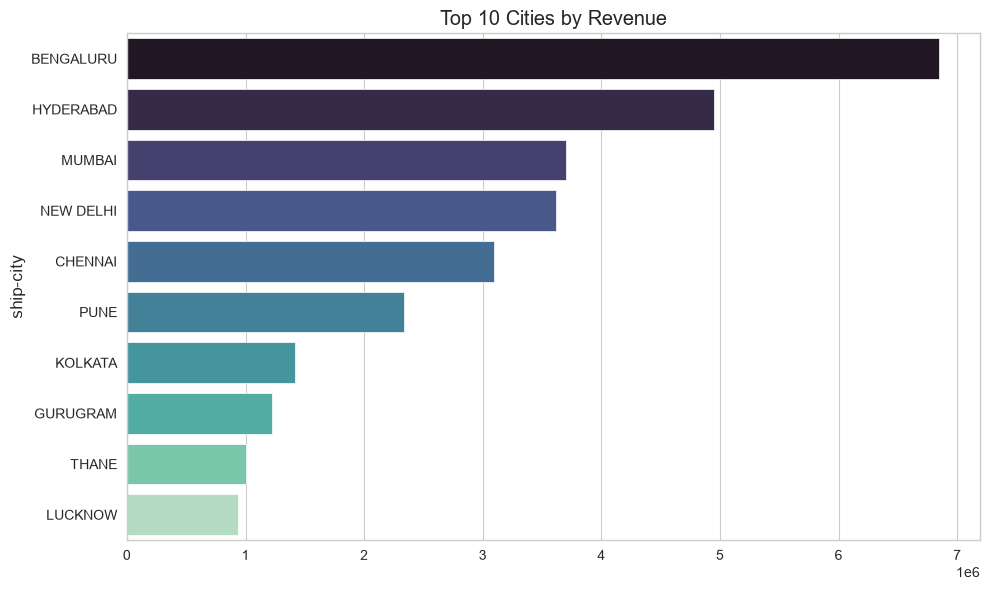

In [28]:
top_cities = (
    df.groupby("ship-city")["Amount"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=top_cities.values,
    y=top_cities.index,
    palette="mako"
)

plt.title("Top 10 Cities by Revenue")

plt.tight_layout()
plt.savefig("../images/top_cities_revenue.png", dpi=300)
plt.show()

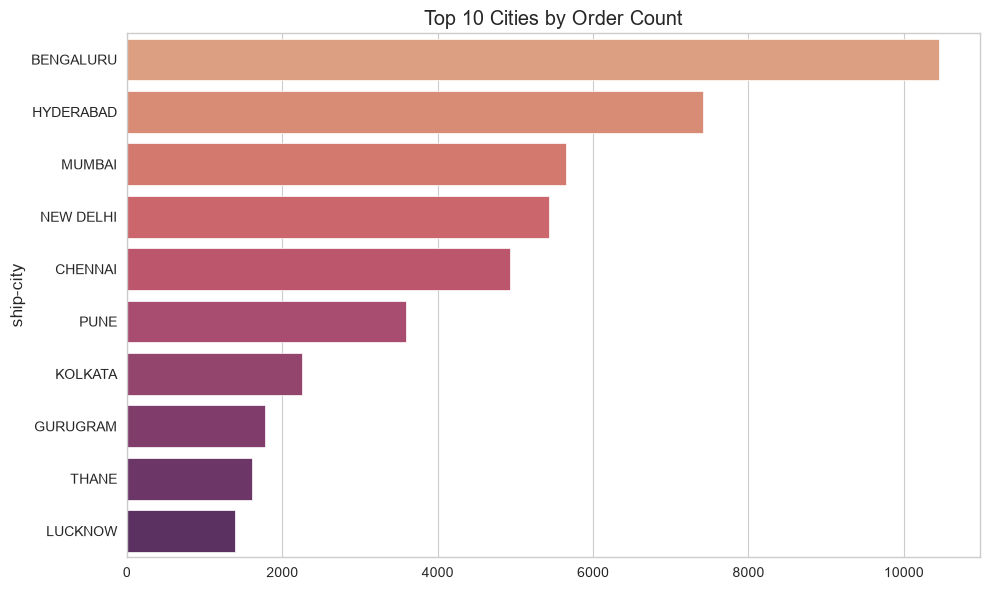

In [29]:
city_orders = (
    df.groupby("ship-city")["Order ID"]
      .nunique()
      .sort_values(ascending=False)
      .head(10)
)

plt.figure(figsize=(10,6))

sns.barplot(
    x=city_orders.values,
    y=city_orders.index,
    palette="flare"
)

plt.title("Top 10 Cities by Order Count")

plt.tight_layout()
plt.savefig("../images/city_orders.png", dpi=300)
plt.show()

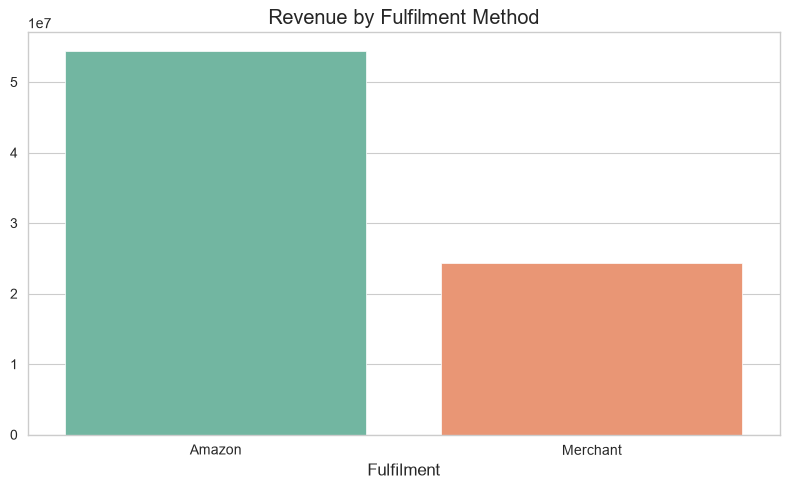

In [30]:
fulfillment = (
    df.groupby("Fulfilment")["Amount"]
      .sum()
      .sort_values(ascending=False)
)

plt.figure(figsize=(8,5))

sns.barplot(
    x=fulfillment.index,
    y=fulfillment.values,
    palette="Set2"
)

plt.title("Revenue by Fulfilment Method")

plt.tight_layout()
plt.savefig("../images/fulfilment_revenue.png", dpi=300)
plt.show()

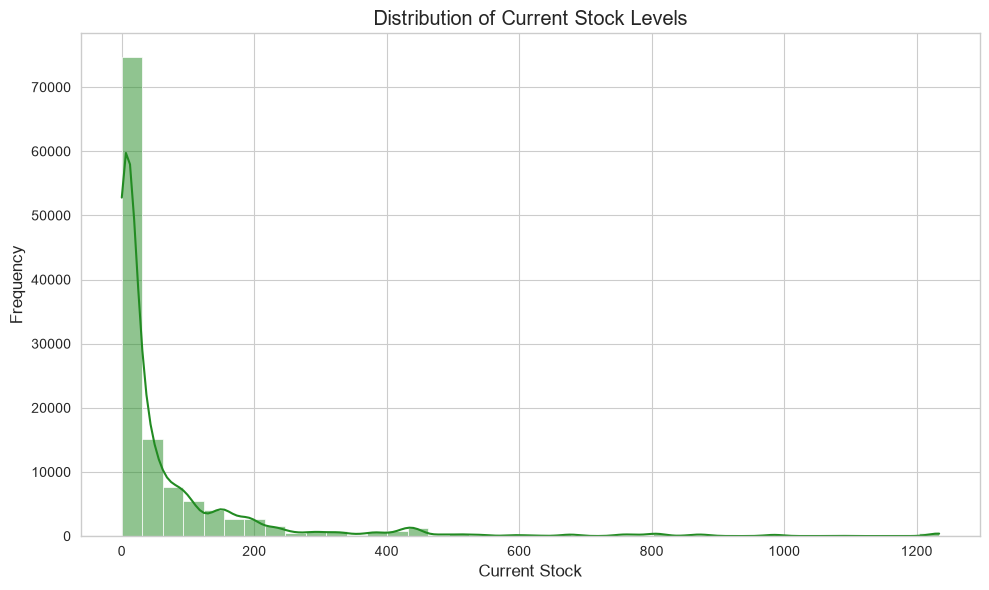

In [31]:
plt.figure(figsize=(10,6))

sns.histplot(
    df["Stock"].dropna(),
    bins=40,
    kde=True,
    color="forestgreen"
)

plt.title("Distribution of Current Stock Levels")
plt.xlabel("Current Stock")
plt.ylabel("Frequency")

plt.tight_layout()

plt.savefig("../images/stock_distribution.png",dpi=300)

plt.show()

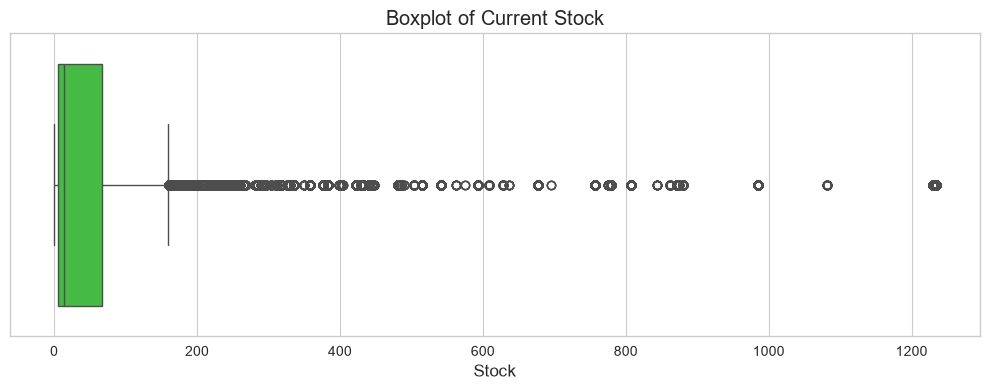

In [32]:
plt.figure(figsize=(10,4))

sns.boxplot(
    x=df["Stock"],
    color="limegreen"
)

plt.title("Boxplot of Current Stock")

plt.tight_layout()

plt.savefig("../images/stock_boxplot.png",dpi=300)

plt.show()

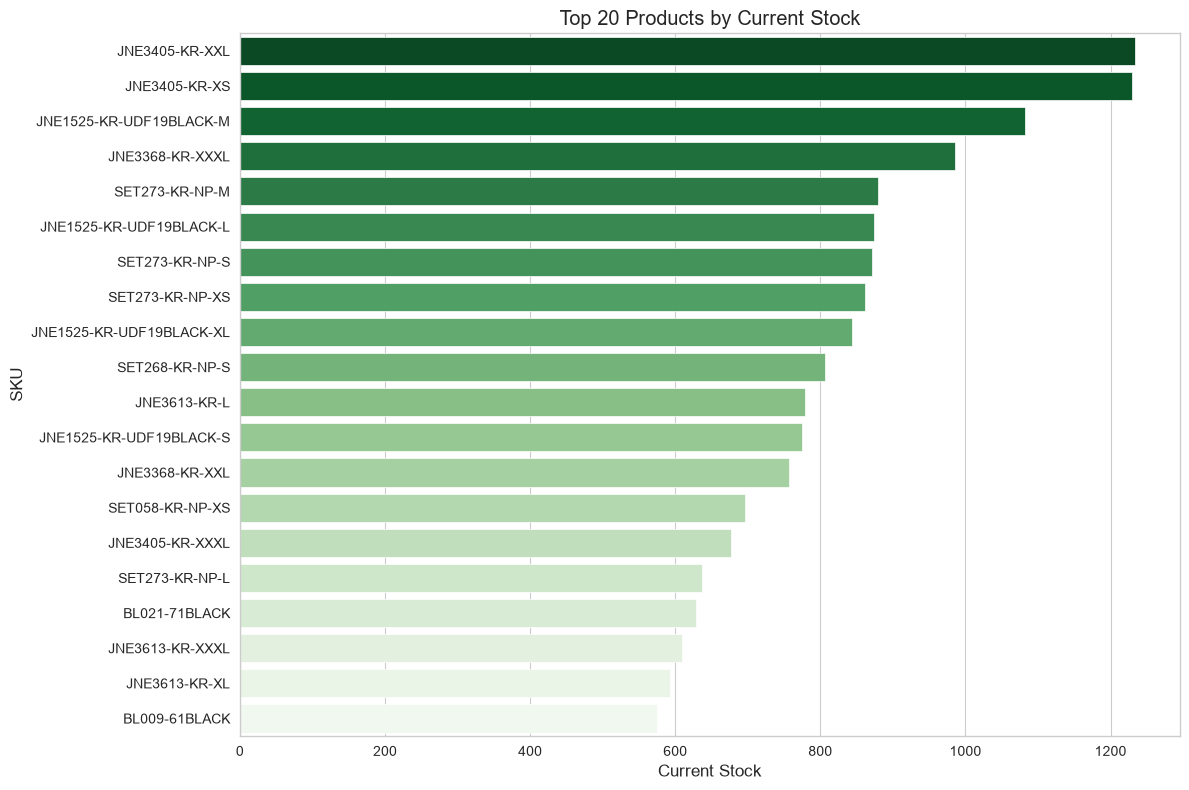

In [33]:
top_stock = (
    df.groupby("SKU")["Stock"]
      .max()
      .sort_values(ascending=False)
      .head(20)
)

plt.figure(figsize=(12,8))

sns.barplot(
    x=top_stock.values,
    y=top_stock.index,
    palette="Greens_r"
)

plt.title("Top 20 Products by Current Stock")

plt.xlabel("Current Stock")

plt.ylabel("SKU")

plt.tight_layout()

plt.savefig("../images/top_stock_products.png",dpi=300)

plt.show()

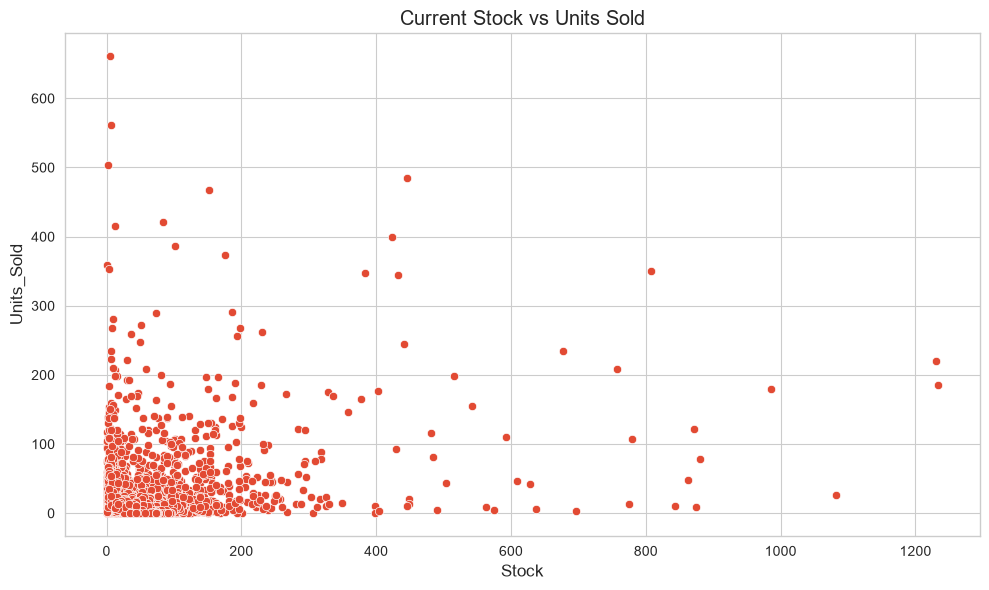

In [34]:
stock_sales = (
    df.groupby("SKU")
      .agg(
          Stock=("Stock","max"),
          Units_Sold=("Qty","sum")
      )
      .reset_index()
)

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=stock_sales,
    x="Stock",
    y="Units_Sold"
)

plt.title("Current Stock vs Units Sold")

plt.tight_layout()

plt.savefig("../images/stock_vs_sales.png",dpi=300)

plt.show()

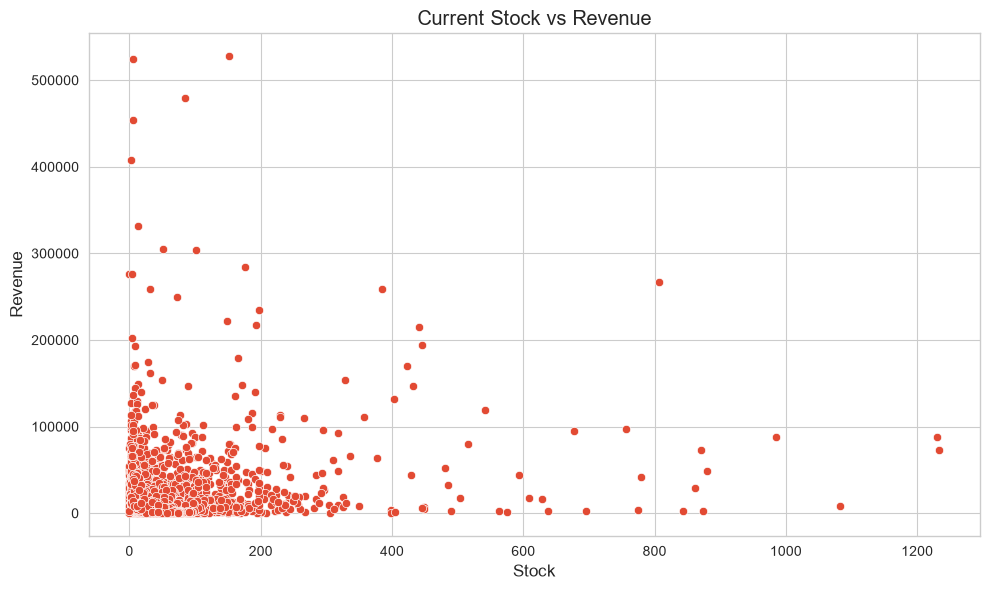

In [35]:
stock_revenue = (
    df.groupby("SKU")
      .agg(
          Stock=("Stock","max"),
          Revenue=("Amount","sum")
      )
      .reset_index()
)

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=stock_revenue,
    x="Stock",
    y="Revenue"
)

plt.title("Current Stock vs Revenue")

plt.tight_layout()

plt.savefig("../images/stock_vs_revenue.png",dpi=300)

plt.show()

In [36]:
inventory = (
    df.groupby("SKU")
      .agg(
          Stock=("Stock","max"),
          Units_Sold=("Qty","sum")
      )
      .reset_index()
)

inventory["Stock_to_Sales"] = (
    inventory["Stock"] /
    inventory["Units_Sold"].replace(0,np.nan)
)

inventory.head()

,SKU,Stock,Units_Sold,Stock_to_Sales
0,AN201-RED-M,5.0,2,2.5
1,AN201-RED-XL,6.0,2,3.0
2,AN201-RED-XXL,3.0,1,3.0
3,AN202-ORANGE-M,3.0,2,1.5
4,AN202-ORANGE-S,16.0,4,4.0


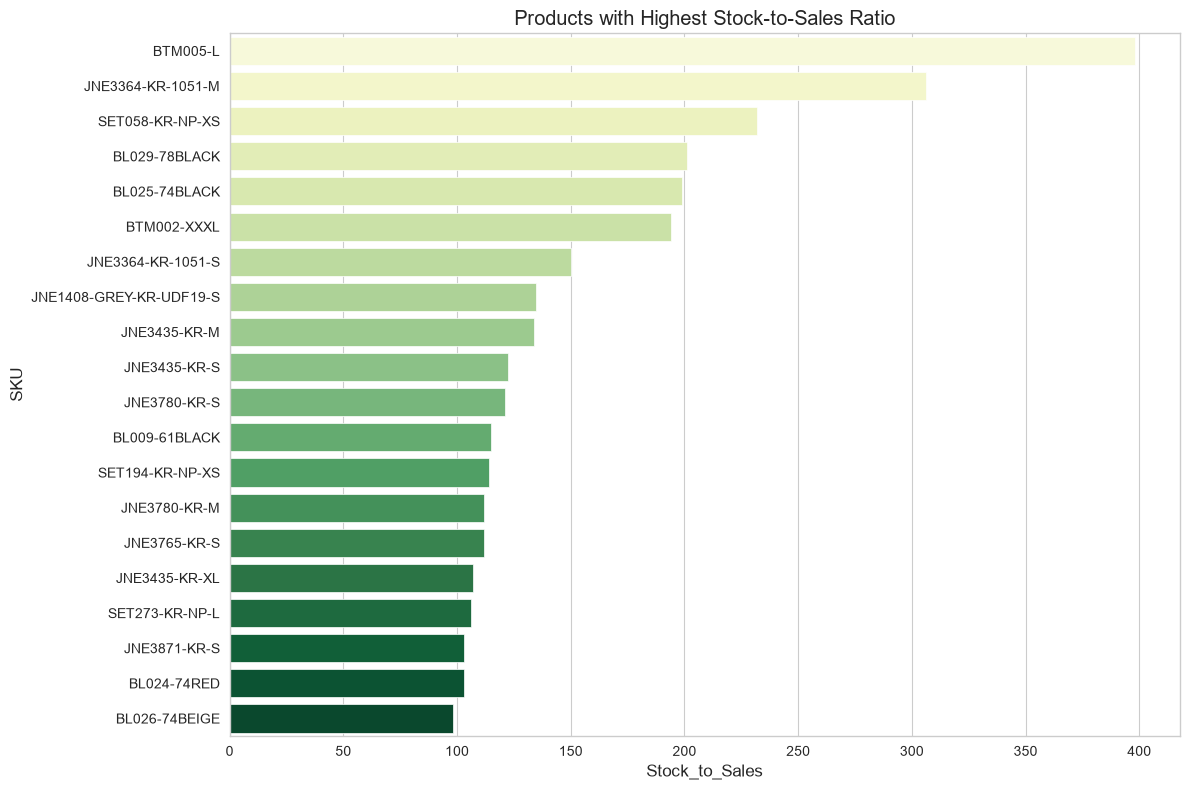

In [37]:
high_ratio = (
    inventory.sort_values(
        "Stock_to_Sales",
        ascending=False
    )
    .head(20)
)

plt.figure(figsize=(12,8))

sns.barplot(
    x=high_ratio["Stock_to_Sales"],
    y=high_ratio["SKU"],
    palette="YlGn"
)

plt.title("Products with Highest Stock-to-Sales Ratio")

plt.tight_layout()

plt.savefig("../images/high_stock_ratio.png",dpi=300)

plt.show()

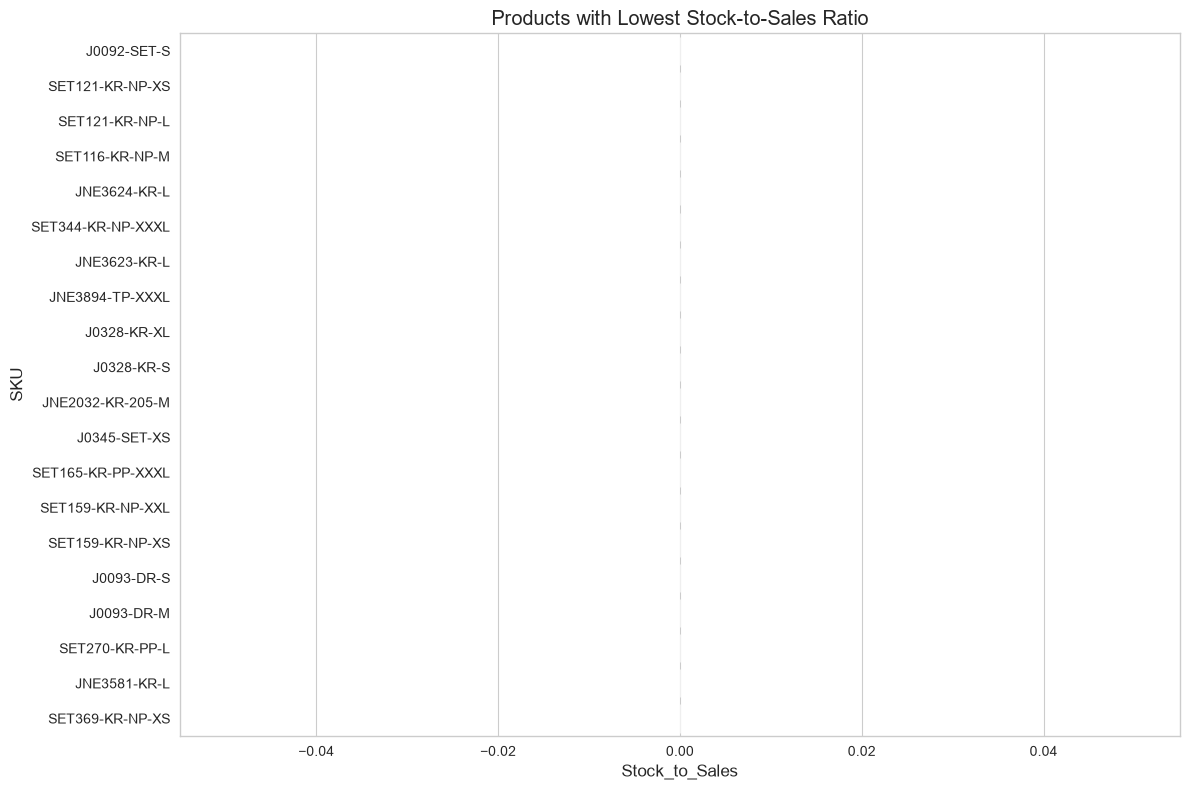

In [38]:
low_ratio = (
    inventory
    .replace([np.inf,-np.inf],np.nan)
    .dropna()
    .sort_values("Stock_to_Sales")
    .head(20)
)

plt.figure(figsize=(12,8))

sns.barplot(
    x=low_ratio["Stock_to_Sales"],
    y=low_ratio["SKU"],
    palette="autumn"
)

plt.title("Products with Lowest Stock-to-Sales Ratio")

plt.tight_layout()

plt.savefig("../images/low_stock_ratio.png",dpi=300)

plt.show()

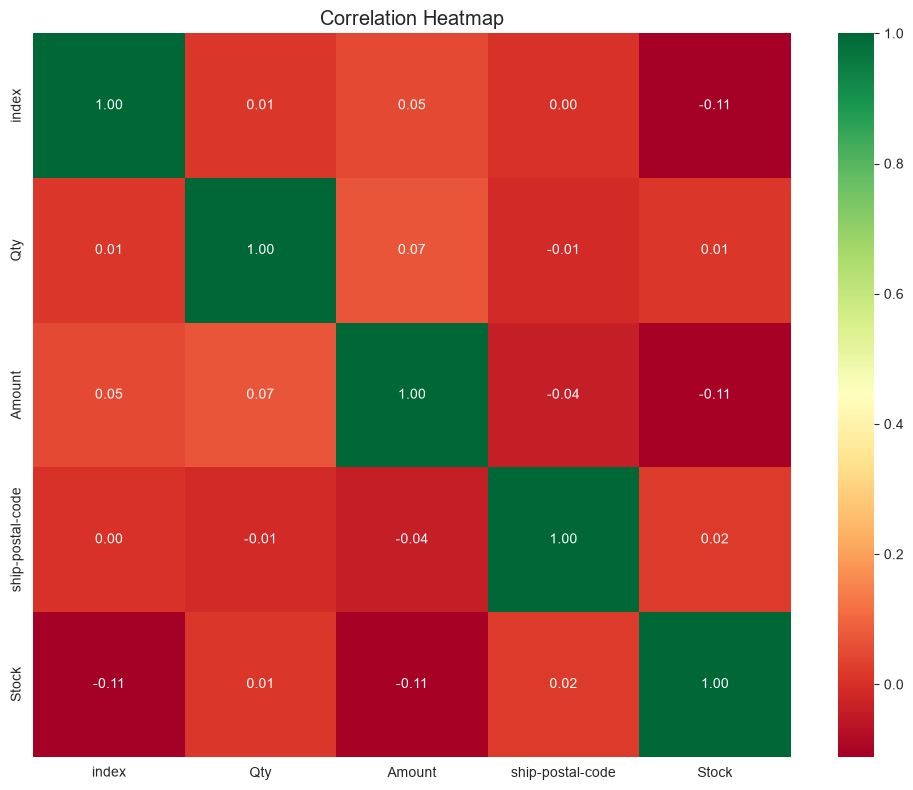

In [39]:
numeric = df.select_dtypes(include=np.number)

plt.figure(figsize=(10,8))

sns.heatmap(
    numeric.corr(),
    annot=True,
    cmap="RdYlGn",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.tight_layout()

plt.savefig("../images/correlation_heatmap.png",dpi=300)

plt.show()

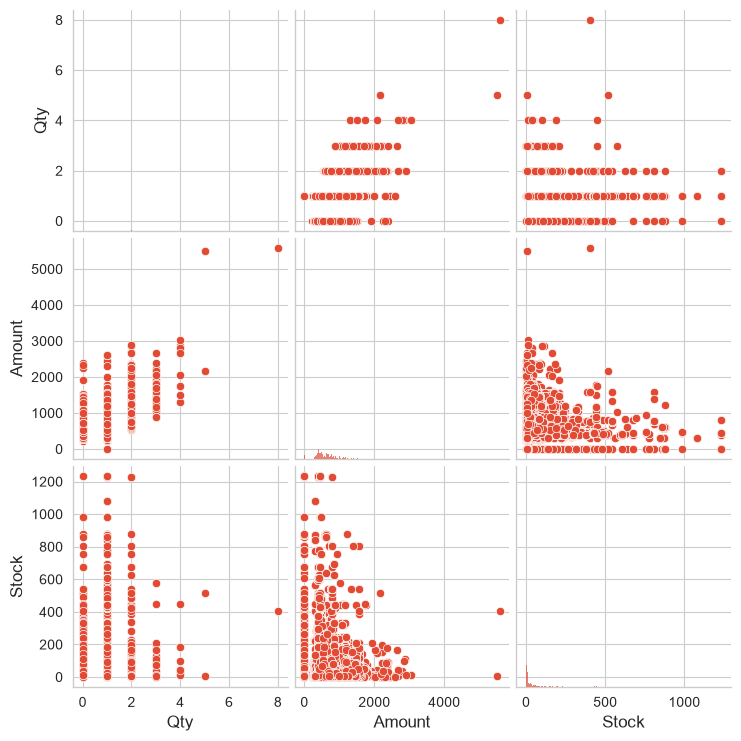

In [40]:
pair = df[
    [
        "Qty",
        "Amount",
        "Stock"
    ]
].dropna()

sns.pairplot(pair)

plt.savefig("../images/pairplot.png",dpi=300)

plt.show()

In [41]:
numeric.corr().round(2)

,index,Qty,Amount,ship-postal-code,Stock
index,1.00,0.01,0.05,0.00,-0.11
Qty,0.01,1.00,0.07,-0.01,0.01
Amount,0.05,0.07,1.00,-0.04,-0.11
ship-postal-code,0.00,-0.01,-0.04,1.00,0.02
Stock,-0.11,0.01,-0.11,0.02,1.00


In [42]:
risk = inventory.copy()

risk["Inventory_Status"] = np.where(
    risk["Stock_to_Sales"] < 1,
    "Low Stock",
    np.where(
        risk["Stock_to_Sales"] > 10,
        "Over Stock",
        "Balanced"
    )
)

risk.head()

,SKU,Stock,Units_Sold,Stock_to_Sales,Inventory_Status
0,AN201-RED-M,5.0,2,2.5,Balanced
1,AN201-RED-XL,6.0,2,3.0,Balanced
2,AN201-RED-XXL,3.0,1,3.0,Balanced
3,AN202-ORANGE-M,3.0,2,1.5,Balanced
4,AN202-ORANGE-S,16.0,4,4.0,Balanced


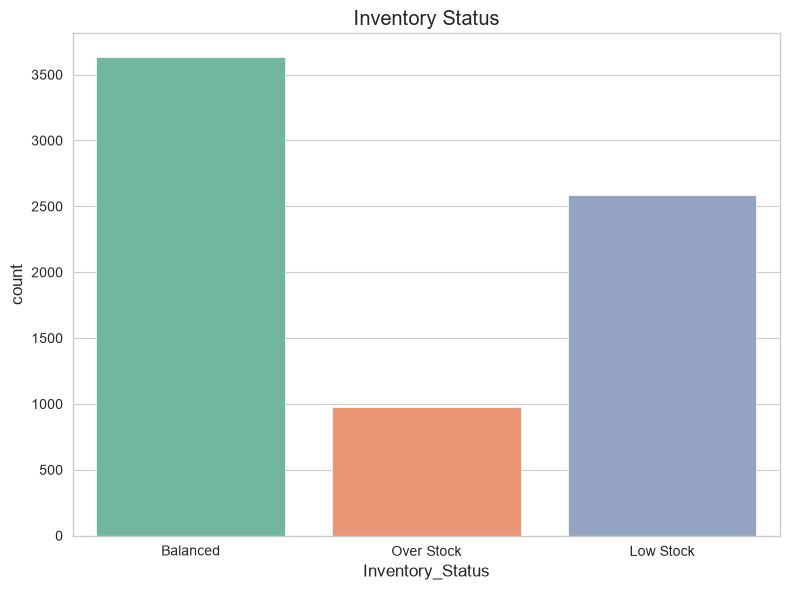

In [43]:
plt.figure(figsize=(8,6))

sns.countplot(
    data=risk,
    x="Inventory_Status",
    palette="Set2"
)

plt.title("Inventory Status")

plt.tight_layout()

plt.savefig("../images/inventory_status.png",dpi=300)

plt.show()